# Inverse problem: which (N, a) give a target R_eff?

The forward sweeps (`effective_resistance_vs_N_a.ipynb`) map (N, a) -> R_eff. This notebook goes
the other way: **given a target R_eff, which (N, a) pairs produce it?**

The short answer is: it's not a unique pair. R_eff appears to collapse (approximately) onto the
combined variable $x = N \cdot a^2$ (the stick-percolation excluded-area parameter), so a whole
*curve* of (N, a) combinations gives roughly the same R_eff -- more, shorter sticks behave like
fewer, longer ones. That assumption is checked, not just assumed (section 3.1).

Approach:
1. Pool every (N, a) -> R_eff sample from the forward sweeps already run (`experiments/exp_*/effective_resistance_sweep_summary*.json`).
2. Fit the empirical power law $R_{eff} \approx A \cdot (N a^2)^{s}$ on that pooled data.
3. **Cross-check the N*a^2 assumption**: fit the more general, unconstrained $R_{eff} \approx A' \cdot N^p \cdot a^q$ and compare -- if $p \not\approx 2q$, the N*a^2 collapse doesn't actually hold and the general fit is used instead.
4. Invert whichever fit wins: for a target R_eff, solve for the (N, a) solution curve.
5. **Validate with new experiments**: for a few target R_eff values, pick candidate (N, a) points off the predicted curve, actually generate percolating networks at those points, and check how close the real R_eff lands to the target.
6. Save the fits and the validation experiment results (as always, via `ExperimentManager`).

---
## 1. Setup and imports

In [1]:
import sys
import os
import glob
import json
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    experiments_dir = "/content/drive/MyDrive/ColabProject/experiments"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    experiments_dir = os.path.abspath(os.path.join(os.getcwd(), "..", "experiments"))
    print("Environment: Local")

if utils_path not in sys.path:
    sys.path.append(utils_path)

print(f"Utils path: {utils_path}")
print(f"Experiments dir: {experiments_dir}")

Environment: Local
Utils path: <project_root>/utils
Experiments dir: <project_root>/experiments


In [2]:
from pipeline_utils import generate_percolating_network, distance_dependent_impedance
from experiment_manager import setup_experiment

R0 = 1000.0  # same distance-dependent resistance scale used throughout the project

print("Imports OK")

Imports OK


---
## 2. Pool every forward-sweep sample seen so far

Scans `experiments/exp_*/` for any `effective_resistance_sweep_summary*.json` (both the small
12-pair sweep and the larger adaptive-grid sweep produce this format) and merges every
(N, a) -> R_eff_values record it finds. Re-running this notebook later, after more sweeps have
been run, automatically picks up the extra data -- nothing here is hardcoded to one experiment.

In [3]:
summary_paths = sorted(glob.glob(os.path.join(experiments_dir, "exp_*", "effective_resistance_sweep_summary*.json")))
print(f"Found {len(summary_paths)} sweep summary file(s):")
for p in summary_paths:
    print(f"  {p}")

merged = defaultdict(list)  # (N, a) -> list of individual R_eff samples (ohm)
for p in summary_paths:
    with open(p) as f:
        summary = json.load(f)
    for rec in summary.get("sweep", []):
        vals = rec.get("R_eff_values") or []
        if vals:
            merged[(rec["N"], round(rec["a"], 3))].extend(vals)

Ns_pts = np.array([k[0] for k in merged])
as_pts = np.array([k[1] for k in merged])
R_mean_pts = np.array([np.mean(v) for v in merged.values()])
n_pts = len(merged)
n_total_trials = sum(len(v) for v in merged.values())

print(f"\n{n_pts} distinct (N, a) points pooled, {n_total_trials} total percolating trials")
print(f"R_eff range: {R_mean_pts.min():.1f} - {R_mean_pts.max():.1f} ohm")
print(f"N range: {Ns_pts.min()} - {Ns_pts.max()}    a range: {as_pts.min():.1f} - {as_pts.max():.1f}")

Found 3 sweep summary file(s):
  <project_root>/experiments/exp_776/effective_resistance_sweep_summary.json
  <project_root>/experiments/exp_781/effective_resistance_sweep_summary.json
  <project_root>/experiments/exp_782/effective_resistance_sweep_summary_ext.json

92 distinct (N, a) points pooled, 2835 total percolating trials
R_eff range: 42.9 - 1092.0 ohm
N range: 20 - 150    a range: 0.2 - 1.0


---
## 3. Fit the collapse: R_eff vs N*a^2

Simple log-log linear regression (`numpy.polyfit`, no scipy needed) on every individual
percolating trial (not just the per-pair means), so pairs with more trials get proportionally
more weight in the fit.

In [4]:
Ns_flat, as_flat, R_flat = [], [], []
for (N, a), vals in merged.items():
    Ns_flat.extend([N] * len(vals))
    as_flat.extend([a] * len(vals))
    R_flat.extend(vals)
Ns_flat = np.array(Ns_flat)
as_flat = np.array(as_flat)
R_flat = np.array(R_flat)

x_flat = Ns_flat * as_flat**2
logx = np.log10(x_flat)
logR = np.log10(R_flat)

slope, intercept = np.polyfit(logx, logR, 1)
A = 10**intercept

pred = slope * logx + intercept
ss_res = np.sum((logR - pred)**2)
ss_tot = np.sum((logR - logR.mean())**2)
r2 = 1 - ss_res / ss_tot

print(f"Fit:  R_eff  ~=  {A:.2f} * (N * a^2) ^ ({slope:.3f})")
print(f"R^2 (log-log) = {r2:.3f}   n = {len(R_flat)} individual trials")

Fit:  R_eff  ~=  2178.86 * (N * a^2) ^ (-0.920)
R^2 (log-log) = 0.776   n = 2835 individual trials


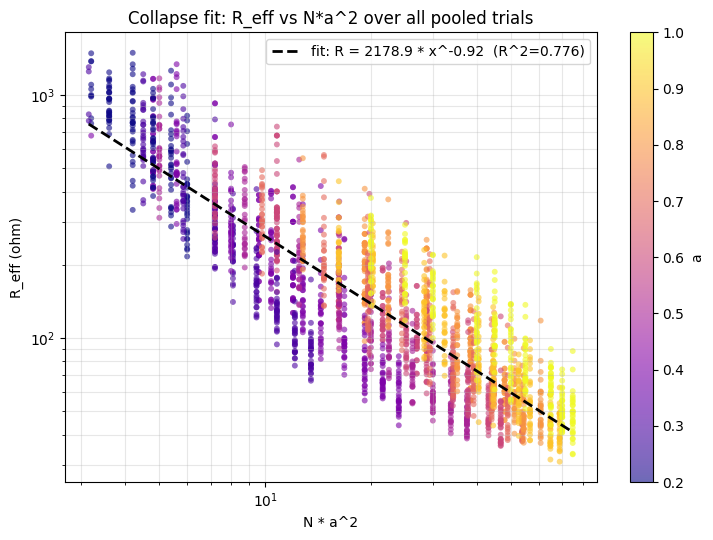

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sc = ax.scatter(x_flat, R_flat, c=as_flat, cmap='plasma', s=18, alpha=0.6, edgecolor='none')
x_line = np.logspace(np.log10(x_flat.min()), np.log10(x_flat.max()), 100)
ax.plot(x_line, A * x_line**slope, 'k--', linewidth=2, label=f'fit: R = {A:.1f} * x^{slope:.2f}  (R^2={r2:.3f})')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('N * a^2'); ax.set_ylabel('R_eff (ohm)')
ax.set_title('Collapse fit: R_eff vs N*a^2 over all pooled trials')
ax.legend()
ax.grid(True, alpha=0.3, which='both')
fig.colorbar(sc, ax=ax, label='a')
plt.tight_layout()
plt.show()

---
### 3.1 Cross-check: does N and a really only enter through N*a^2?

The fit above forces the exponents to 1 on N and 2 on a (i.e. R_eff depends on N and a only
through the combined variable N*a^2). That combination is well-justified for the *percolation
threshold* (it's the mean-crossings-per-stick excluded-area parameter from continuum
stick-percolation theory), but nothing guarantees R_eff itself -- away from the threshold --
collapses onto exactly the same variable.

So here we fit the more general, unconstrained form $R_{eff} \approx A' \cdot N^p \cdot a^q$ and
check whether $p$ ends up close to $2q$. If it does, the N*a^2 collapse is a good description of
this data; if not, this more general fit should be trusted instead, and is used for the
inversion in section 4.

In [6]:
X = np.column_stack([np.ones_like(logx), np.log10(Ns_flat), np.log10(as_flat)])
coef, *_ = np.linalg.lstsq(X, logR, rcond=None)
log_Ap, p_exp, q_exp = coef
Ap = 10**log_Ap

pred_general = X @ coef
ss_res_g = np.sum((logR - pred_general) ** 2)
r2_general = 1 - ss_res_g / ss_tot

print(f"General fit:   R_eff ~= {Ap:.2f} * N^{p_exp:.3f} * a^{q_exp:.3f}   [R^2 = {r2_general:.3f}]")
print(f"N*a^2 fit:     R_eff ~= {A:.2f} * (N*a^2)^{slope:.3f}             [R^2 = {r2:.3f}]")
print(f"\np = {p_exp:.3f}   2*q = {2 * q_exp:.3f}   (ratio p/(2q) = {p_exp / (2 * q_exp):.3f}; "
      f"close to 1.0 means the N*a^2 collapse is well justified)")

use_general = r2_general > r2 + 0.01  # only switch models if the improvement isn't just noise
print(f"\n-> Using the {'GENERAL' if use_general else 'N*a^2'} fit for the inversion below "
      f"({'higher R^2 by > 0.01' if use_general else 'the two fits are close enough that the simpler model is preferred'}).")

def predict_N(R_target, a):
    """N required to hit R_target at a given a, per whichever fit scored better above."""
    if use_general:
        return 10 ** ((np.log10(R_target / Ap) - q_exp * np.log10(a)) / p_exp)
    x_t = 10 ** ((np.log10(R_target) - intercept) / slope)
    return x_t / a**2

General fit:   R_eff ~= 10246.37 * N^-1.283 * a^-1.746   [R^2 = 0.848]
N*a^2 fit:     R_eff ~= 2178.86 * (N*a^2)^-0.920             [R^2 = 0.776]

p = -1.283   2*q = -3.491   (ratio p/(2q) = 0.367; close to 1.0 means the N*a^2 collapse is well justified)

-> Using the GENERAL fit for the inversion below (higher R^2 by > 0.01).


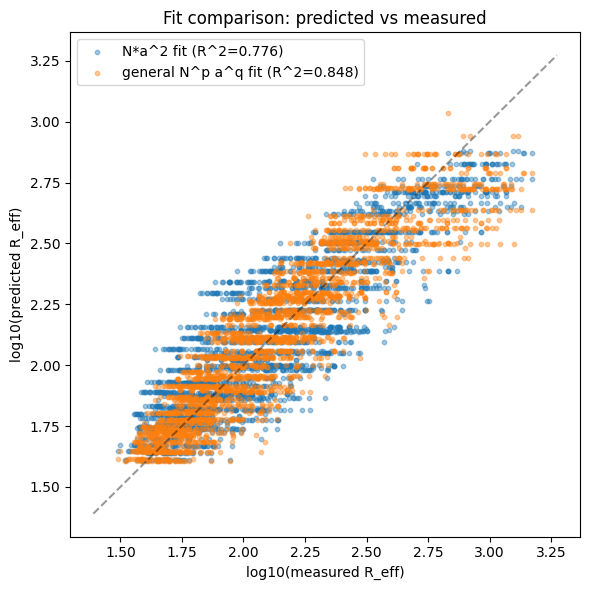

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(logR, pred, s=10, alpha=0.4, label=f'N*a^2 fit (R^2={r2:.3f})')
ax.scatter(logR, pred_general, s=10, alpha=0.4, label=f'general N^p a^q fit (R^2={r2_general:.3f})')
lims = [logR.min() - 0.1, logR.max() + 0.1]
ax.plot(lims, lims, 'k--', alpha=0.4)
ax.set_xlabel('log10(measured R_eff)'); ax.set_ylabel('log10(predicted R_eff)')
ax.set_title('Fit comparison: predicted vs measured')
ax.legend()
plt.tight_layout()
plt.show()

---
## 4. Invert: solution curve for a target R_eff

The fit only constrains the product $x = N a^2$, so for a target R_eff there's a whole curve of
valid (N, a) -- not a single point. We trace that curve for several representative targets, chosen
from the actual data range (5th/15th/30th/50th/70th/85th/95th percentile of the pooled mean
R_eff) so we're interpolating, not extrapolating far beyond what's been measured -- widened from
the original 3 percentiles (15/50/85) to cover the tails too, now that section 6's validation is
scaled up to match.

In [ ]:
def x_for_target(R_target):
    """Required N*a^2 to hit a target R_eff, per the N*a^2 power law."""
    return 10 ** ((np.log10(R_target) - intercept) / slope)

def solution_curve_simple(R_target, a_values, N_bounds=(10, 400)):
    x_t = x_for_target(R_target)
    a_arr = np.asarray(a_values)
    N_arr = x_t / a_arr**2
    mask = (N_arr >= N_bounds[0]) & (N_arr <= N_bounds[1])
    return N_arr[mask], a_arr[mask]

def solution_curve_general(R_target, a_values, N_bounds=(10, 400)):
    a_arr = np.asarray(a_values)
    logN = (np.log10(R_target / Ap) - q_exp * np.log10(a_arr)) / p_exp
    N_arr = 10 ** logN
    mask = (N_arr >= N_bounds[0]) & (N_arr <= N_bounds[1])
    return N_arr[mask], a_arr[mask]

targets_demo = [float(round(v, -1)) for v in np.percentile(R_mean_pts, [5, 15, 30, 50, 70, 85, 95])]
print(f"Demo targets (5/15/30/50/70/85/95th percentile of measured R_eff): {targets_demo} ohm")

a_grid = np.linspace(0.05, 1.2, 300)
palette = plt.cm.tab10.colors

fig, ax = plt.subplots(figsize=(8, 6.5))
sc = ax.scatter(Ns_pts, as_pts, c=np.log10(R_mean_pts), cmap='viridis_r', s=45,
                 edgecolor='k', linewidth=0.3, zorder=3, label='measured sweep points')
for i, R_t in enumerate(targets_demo):
    color = palette[i % len(palette)]
    N_simple, a_simple = solution_curve_simple(R_t, a_grid)
    N_general, a_general = solution_curve_general(R_t, a_grid)
    ax.plot(N_simple, a_simple, linewidth=2, linestyle='--', color=color,
            label=f'R_eff={R_t:.0f} ohm  (N*a^2 fit)')
    ax.plot(N_general, a_general, linewidth=2.5, linestyle='-', color=color,
            label=f'R_eff={R_t:.0f} ohm  (general fit)')
ax.set_xlabel('N'); ax.set_ylabel('a')
ax.set_title('Solution curves for a few target R_eff\n'
             f'(solid = general N^p a^q fit, dashed = N*a^2 fit; '
             f'inversion below uses the {"general" if use_general else "N*a^2"} one)')
ax.legend(fontsize=7, ncol=1, loc='upper right')
fig.colorbar(sc, ax=ax, label='log10(measured mean R_eff)')
plt.tight_layout()
plt.show()

---
## 5. Cross-check: nearest already-measured points

An independent sanity check on the fit -- for each target, which already-measured (N, a) points
came closest to it in practice?

In [9]:
def nearest_points(R_target, k=5):
    d = np.abs(np.log10(R_mean_pts) - np.log10(R_target))
    return np.argsort(d)[:k]

for R_t in targets_demo:
    print(f"\nNearest measured points to R_eff = {R_t:.0f} ohm:")
    for i in nearest_points(R_t):
        print(f"  N={Ns_pts[i]:4d}  a={as_pts[i]:.2f}   mean R_eff={R_mean_pts[i]:8.1f} ohm")


Nearest measured points to R_eff = 60 ohm:
  N=  80  a=0.80   mean R_eff=    59.9 ohm
  N= 150  a=0.40   mean R_eff=    60.3 ohm
  N=  65  a=0.90   mean R_eff=    60.3 ohm
  N= 120  a=0.50   mean R_eff=    61.7 ohm
  N=  75  a=0.80   mean R_eff=    62.8 ohm

Nearest measured points to R_eff = 120 ohm:
  N=  80  a=0.50   mean R_eff=   118.0 ohm
  N=  40  a=1.00   mean R_eff=   117.0 ohm
  N=  40  a=0.90   mean R_eff=   116.3 ohm
  N=  60  a=0.70   mean R_eff=   114.5 ohm
  N= 105  a=0.40   mean R_eff=   113.8 ohm

Nearest measured points to R_eff = 400 ohm:
  N= 150  a=0.20   mean R_eff=   390.8 ohm
  N=  45  a=0.40   mean R_eff=   410.7 ohm
  N=  20  a=0.60   mean R_eff=   412.0 ohm
  N=  35  a=0.50   mean R_eff=   324.4 ohm
  N=  20  a=0.70   mean R_eff=   324.1 ohm


---
## 6. Validate the inversion with new experiments

For each demo target, pick four candidates off its solution curve, spanning compact to sparse
(`a` = 0.2, 0.4, 0.7, 1.0) -- widened from the original 2 (0.3/0.8) now that section 4 also
covers 7 targets instead of 3, so this checks the inversion across more of the (N, a) plane, not
just its middle. Node count is capped the same way as the extended forward sweep, so this stays
cheap per-network even if a solution curve would otherwise wander into the dense (high-N, high-a)
corner -- though with 7 targets x 4 candidates x `n_trials_val` trials each, the total network
count is now comparable to the forward sweep's own scale, so this section is the one worth
running on the cluster rather than locally.

In [ ]:
def safe_candidate(N, a, node_cap=3000, N_floor=10):
    N = int(round(N))
    a = float(np.clip(a, 0.05, 1.2))
    nodes_est = 0.5 * N**2 * a**2
    if nodes_est > node_cap:
        N = int(np.sqrt(node_cap / (0.5 * a**2)))
    return max(N, N_floor), a

validation_plan = []
for R_t in targets_demo:
    for a_c, tag in [(0.2, "very-compact"), (0.4, "compact-ish"), (0.7, "sparse-ish"), (1.0, "very-sparse")]:
        N_c, a_c = safe_candidate(predict_N(R_t, a_c), a_c)
        validation_plan.append({"R_target": R_t, "N": N_c, "a": a_c, "tag": tag})

print(f"{len(validation_plan)} validation candidates (predicted with the "
      f"{'general' if use_general else 'N*a^2'} fit):")
for v in validation_plan:
    print(f"  target={v['R_target']:7.1f} ohm   N={v['N']:4d}  a={v['a']:.2f}   ({v['tag']})")

In [ ]:
n_trials_val = 30
max_attempts_val = 200

exp_manager_val = setup_experiment()

In [ ]:
cluster_dir = os.path.abspath(os.path.join(os.getcwd(), "..", "cluster"))
cache_dir = os.path.join(cluster_dir, "validation_results")
cache_files = [os.path.join(cache_dir, f"candidate_{i:02d}.json") for i in range(len(validation_plan))]
use_cache = len(validation_plan) > 0 and all(os.path.exists(p) for p in cache_files)

validation_results = []

if use_cache:
    print(f"Found all {len(validation_plan)} candidate results cached in {cache_dir} "
          f"(from the parallel SLURM array run) -- loading instead of recomputing.")
    for p in cache_files:
        with open(p) as f:
            validation_results.append(json.load(f))
        v = validation_results[-1]
        mean_str = f"{v['achieved_mean_ohm']:8.1f}" if v['achieved_mean_ohm'] is not None else "     n/a"
        err_str = f"{v['relative_error'] * 100:+6.1f}%" if v['relative_error'] is not None else "   n/a"
        print(f"target={v['R_target']:7.1f} ohm   N={v['N']:4d} a={v['a']:.2f} ({v['tag']:13s})   "
              f"achieved mean={mean_str} ohm   rel.err={err_str}")
else:
    if os.path.isdir(cache_dir):
        print(f"Cache dir {cache_dir} exists but is incomplete "
              f"({sum(os.path.exists(p) for p in cache_files)}/{len(validation_plan)} candidates) -- recomputing all.")
    for plan in validation_plan:
        N, a, R_t = plan["N"], plan["a"], plan["R_target"]
        seed_base = (hash((N, round(a, 3), "inverse_validation")) % 100000)
        np.random.seed(seed_base)

        R_effs = []
        total_attempts = 0
        while len(R_effs) < n_trials_val:
            res, attempts = generate_percolating_network(N, a, k_uniform=R0, max_attempts=max_attempts_val)
            total_attempts += attempts
            if res is None:
                print(f"  [WARNING] N={N} a={a}: gave up after {total_attempts} draws, "
                      f"only found {len(R_effs)}/{n_trials_val}")
                break
            rl = distance_dependent_impedance(res, R0)
            R_effs.append(rl['impedance'])

        achieved_mean = float(np.mean(R_effs)) if R_effs else None
        rel_err = (achieved_mean - R_t) / R_t if achieved_mean else None
        validation_results.append({
            "R_target": R_t, "N": N, "a": a, "tag": plan["tag"], "n": len(R_effs),
            "achieved_mean_ohm": achieved_mean,
            "achieved_median_ohm": float(np.median(R_effs)) if R_effs else None,
            "achieved_std_ohm": float(np.std(R_effs)) if R_effs else None,
            "relative_error": rel_err,
            "R_eff_values": R_effs,
        })
        mean_str = f"{achieved_mean:8.1f}" if achieved_mean is not None else "     n/a"
        err_str = f"{rel_err * 100:+6.1f}%" if rel_err is not None else "   n/a"
        print(f"target={R_t:7.1f} ohm   N={N:4d} a={a:.2f} ({plan['tag']:13s})   "
              f"achieved mean={mean_str} ohm   rel.err={err_str}")

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
targets_v = [v["R_target"] for v in validation_results if v["achieved_mean_ohm"] is not None]
achieved_v = [v["achieved_mean_ohm"] for v in validation_results if v["achieved_mean_ohm"] is not None]
tags_v = [v["tag"] for v in validation_results if v["achieved_mean_ohm"] is not None]

colors = {"very-compact": "tab:red", "compact-ish": "tab:blue",
          "sparse-ish": "tab:orange", "very-sparse": "tab:green"}
for tag in set(tags_v):
    xs = [t for t, tg in zip(targets_v, tags_v) if tg == tag]
    ys = [a for a, tg in zip(achieved_v, tags_v) if tg == tag]
    ax.scatter(xs, ys, s=80, label=tag, color=colors.get(tag), edgecolor='k', linewidth=0.5)

if targets_v and achieved_v:
    lims = [min(targets_v + achieved_v) * 0.7, max(targets_v + achieved_v) * 1.3]
    ax.plot(lims, lims, 'k--', alpha=0.5, label='perfect inversion')
    ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('target R_eff (ohm)'); ax.set_ylabel('achieved mean R_eff (ohm)')
ax.set_title('Inversion validation: target vs achieved R_eff')
ax.legend()
ax.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()
exp_manager_val.save_figure(fig, "inversion_validation_target_vs_achieved.png")

---
## 7. Save results

In [14]:
summary = {
    "experiment": exp_manager_val.get_info(),
    "forward_data_sources": summary_paths,
    "n_pooled_points": n_pts,
    "n_pooled_trials": n_total_trials,
    "fit_Na2": {"slope": float(slope), "intercept": float(intercept), "A": float(A), "r2": float(r2),
                "model": "R_eff = A * (N * a^2) ^ slope"},
    "fit_general": {"A": float(Ap), "p": float(p_exp), "q": float(q_exp), "r2": float(r2_general),
                     "model": "R_eff = A * N^p * a^q"},
    "used_fit_for_inversion": "general" if use_general else "N*a^2",
    "targets_demo": targets_demo,
    "validation_plan": validation_plan,
    "validation_results": validation_results,
}

exp_manager_val.save_json(summary, "inverse_problem_summary.json")

print(f"\nAll results saved to: {exp_manager_val.experiment_dir}")
for f in sorted(os.listdir(exp_manager_val.experiment_dir)):
    print(f"  - {f}")

  [OK] JSON saved: inverse_problem_summary.json

All results saved to: <project_root>/utils/../experiments/exp_783
  - inverse_problem_summary.json
  - inversion_validation_target_vs_achieved.png


---
## Notes

- The N*a^2 collapse is not assumed blindly -- section 3.1 fits the general, unconstrained form
  $R_{eff} \approx A' N^p a^q$ and compares its R^2 and its $p$ vs $2q$ to the single-variable
  fit. The inversion in section 4 automatically uses whichever of the two fits the data actually
  supports better (see the printed `use_general` decision), rather than assuming the excluded-area
  variable that governs the *percolation threshold* also governs R_eff away from it.
- Either way, the inversion is fundamentally underdetermined: a target R_eff pins down a *curve*
  of (N, a) solutions, not a single pair (more, shorter sticks behave like fewer, longer ones).
  Picking one specific (N, a) off that curve requires an extra constraint from outside this model
  (e.g. a fabrication limit on how many sticks you can place, or on how long they can be).
- The validation experiments are an honest out-of-sample check: they redraw brand-new random
  networks at the candidate (N, a) rather than reusing anything from the fit, so the reported
  relative error reflects how well the chosen model actually predicts new draws (including their
  run-to-run variance), not just goodness-of-fit on the training data.
- Re-running this notebook after further forward sweeps (larger N, more (N, a) pairs, more
  trials per pair) will automatically pool the extra data in section 2 and sharpen both fits --
  nothing about the data loading is tied to one specific experiment folder.